<a href="https://colab.research.google.com/github/eshaans1305/BIS_lab/blob/main/1BM24CS096_Week2_Zomato_PSO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Enter the number of orders to simulate: 15

Starting Particle Swarm Optimization Route Alignment for 15 orders...

Generation 001: Minimum Route Distance = 141.63 km
Generation 020: Minimum Route Distance = 118.39 km
Generation 040: Minimum Route Distance = 101.87 km
Generation 060: Minimum Route Distance = 86.52 km
Generation 080: Minimum Route Distance = 86.52 km
Generation 100: Minimum Route Distance = 86.23 km
Generation 120: Minimum Route Distance = 86.23 km
Generation 140: Minimum Route Distance = 86.05 km
Generation 160: Minimum Route Distance = 86.05 km
Generation 180: Minimum Route Distance = 86.05 km
Generation 200: Minimum Route Distance = 86.05 km

================ METRICS & RESULTS ================
Optimized Route Chain:
Hub (0) -> Rest(5) -> Rest(3) -> Rest(8) -> Rest(15) -> Rest(14) -> Rest(6) -> Rest(1) -> Rest(4) -> Rest(9) -> Cust(3) -> Rest(2) -> Rest(7) -> Cust(15) -> Rest(11) -> Cust(5) -> Rest(13) -> Cust(7) -> Rest(12) -> Cust(12) -> Cust(1) -> Cust(6) -> Cust(8)

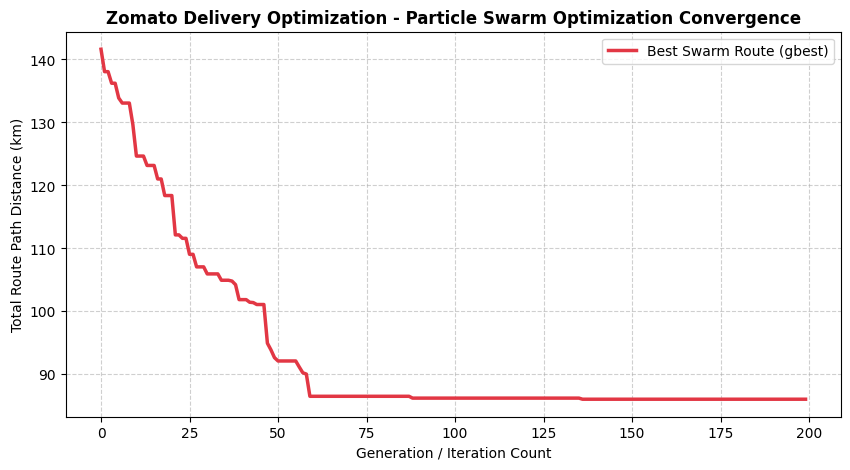

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import random

NUM_ORDERS = int(input("Enter the number of orders to simulate: "))

POP_SIZE = 100
GENERATIONS = 200
W = 0.5
C1 = 1.5
C2 = 1.5
PENALTY_VALUE = 999999

np.random.seed(42)
random.seed(42)

coordinates = np.random.uniform(0, 10, size=(2 * NUM_ORDERS + 1, 2))

def calculate_distance_matrix(coords):
    num_nodes = len(coords)
    matrix = np.zeros((num_nodes, num_nodes))
    for i in range(num_nodes):
        for j in range(num_nodes):
            matrix[i][j] = np.linalg.norm(coords[i] - coords[j])
    return matrix

distance_matrix = calculate_distance_matrix(coordinates)

def is_valid_route(route):
    for i in range(1, NUM_ORDERS + 1):
        try:
            restaurant_idx = route.index(i)
            customer_idx = route.index(i + NUM_ORDERS)
            if customer_idx < restaurant_idx:
                return False
        except ValueError:
            return False
    return True

def create_valid_individual():
    elements = list(range(1, 2 * NUM_ORDERS + 1))
    while True:
        random.shuffle(elements)
        if is_valid_route(elements):
            return elements

def route_to_position(route):
    x = np.zeros(len(route))
    for pos, node in enumerate(route):
        x[node - 1] = pos
    return x

def decode_position(x):
    return (np.argsort(x) + 1).tolist()

def compute_fitness(individual_route):
    full_route = [0] + individual_route + [0]

    if not is_valid_route(individual_route):
        return 1.0 / PENALTY_VALUE

    total_dist = 0.0
    for i in range(len(full_route) - 1):
        total_dist += distance_matrix[full_route[i]][full_route[i+1]]

    return 1.0 / total_dist

X = []
V = []

for _ in range(POP_SIZE):
    valid_route = create_valid_individual()
    X.append(route_to_position(valid_route))
    V.append(np.random.uniform(-1.0, 1.0, size=2 * NUM_ORDERS))

X = np.array(X)
V = np.array(V)

pbest_X = X.copy()
pbest_fitness = np.array([compute_fitness(decode_position(pos)) for pos in X])

gbest_idx = np.argmax(pbest_fitness)
gbest_X = pbest_X[gbest_idx].copy()
gbest_fitness_val = pbest_fitness[gbest_idx]

history_best_distance = []

print(f"\nStarting Particle Swarm Optimization Route Alignment for {NUM_ORDERS} orders...\n")

for gen in range(GENERATIONS):
    for i in range(POP_SIZE):
        r1 = np.random.uniform(0, 1, size=2 * NUM_ORDERS)
        r2 = np.random.uniform(0, 1, size=2 * NUM_ORDERS)

        V[i] = (W * V[i] +
                C1 * r1 * (pbest_X[i] - X[i]) +
                C2 * r2 * (gbest_X - X[i]))

        X[i] = X[i] + V[i]

        current_route = decode_position(X[i])
        current_fit = compute_fitness(current_route)

        if current_fit > pbest_fitness[i]:
            pbest_fitness[i] = current_fit
            pbest_X[i] = X[i].copy()

    best_swarm_idx = np.argmax(pbest_fitness)
    if pbest_fitness[best_swarm_idx] > gbest_fitness_val:
        gbest_fitness_val = pbest_fitness[best_swarm_idx]
        gbest_X = pbest_X[best_swarm_idx].copy()

    best_distance = 1.0 / gbest_fitness_val if gbest_fitness_val > 0 else PENALTY_VALUE
    history_best_distance.append(best_distance)

    if (gen + 1) % 20 == 0 or gen == 0:
        print(f"Generation {gen+1:03d}: Minimum Route Distance = {best_distance:.2f} km")

optimized_sequence = decode_position(gbest_X)
optimized_distance = 1.0 / gbest_fitness_val

clean_route = "Hub (0) -> " + " -> ".join(
    f"Rest({node})" if node <= NUM_ORDERS else f"Cust({node - NUM_ORDERS})" for node in optimized_sequence
) + " -> Hub (0)"

print("\n================ METRICS & RESULTS ================")
print(f"Optimized Route Chain:\n{clean_route}")
print(f"Final Minimum Driving Distance: {optimized_distance:.2f} km")

plt.figure(figsize=(10, 5))
plt.plot(history_best_distance, color='#E23744', linewidth=2.5, label='Best Swarm Route (gbest)')
plt.title('Zomato Delivery Optimization - Particle Swarm Optimization Convergence', fontsize=12, fontweight='bold')
plt.xlabel('Generation / Iteration Count', fontsize=10)
plt.ylabel('Total Route Path Distance (km)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()
